# MUC02 — Credit Pre-Screening Engine: Loan Intake Optimisation

**Calibo AI Academy · Path 2 · KLU Batch · Phase 2 — Mini Use Case 02 (Supervised Learning Part 1)**
**Industry:** BFSI — Retail Lending (Personal Loans)

**Team:** Lohitha · Ashika · Suresh · Akhilandra

| Team member | Role | Sections built |
|---|---|---|
| **Lohitha** | Data Analyst (lead) | CBIM Problem Canvas, Steps 5.1 (A–D) |
| **Ashika** | Data Analyst | Steps 5.2 and 5.3 |
| **Suresh** | Model Builder | Steps 5.4 and 5.5 |
| **Akhilandra** | Policy Synthesiser | Steps 5.6 and 5.7 (Credit Policy Briefing) |

## 1. Introduction

Credit pre-screening is an important process in lending that helps financial institutions assess loan applications before making final credit decisions. A mid-size private bank receives about 3,000 personal-loan applications a month and manually reviews every one for about 25 minutes. Close to half are declined, many within the first minute.

This use case uses six months of historical decisions (12,000 applications, April–September 2026) to ask whether a pre-screening model can safely remove clear-cut declines from the manual review queue.

## 2. Business Objective

Analyse historical credit applications, identify the factors behind approval and decline decisions, engineer affordability features, build a Logistic Regression model that predicts **Declined**, and choose an **auto-decline threshold** that keeps wrongly declined applications within the bank's 5% risk limit — then express the result in applications and analyst hours per month.

## 3. Key Objectives

- Understand the structure and quality of the dataset and document every cleaning decision.
- Find what drives approval decisions today (credit score, employment type, FOIR).
- Build FOIR, loan-to-income and new-to-credit features.
- Train and evaluate a Logistic Regression model with `Declined = 1`.
- Choose a safe auto-decline threshold using the 5% rule and quantify the monthly impact.
- Check the model for fairness by gender and finish with a Credit Policy Briefing.

## 4. Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

**Before submitting:** run **Kernel → Restart & Run All** and confirm there are no errors. The dataset CSV must be in the same folder as this notebook.

# CBIM Problem Canvas
*Completed by the whole team before any analysis. (Lohitha, reviewed by all.)*

| Canvas element | Our answer |
|---|---|
| **Situation (S)** | A mid-size private bank receives about **3,000 personal-loan applications a month**. Every application goes through a manual credit review of about **25 minutes**, and close to half end up declined. |
| **Complication (C)** | Analyst time is spent on clear-cut declines (very low credit score, or EMIs already consuming most of the income) that are decided in the first minute. Good applicants wait longer in the same queue, and the bank cannot handle more volume without hiring more analysts. |
| **Question (Q)** | Which applications can be **safely removed from manual review** and auto-declined, and at what model-confidence threshold — without more than **5%** of the auto-declined applications being ones the credit team would have approved? |
| **SSOT** | `MUC02_Credit_PreScreening_Dataset.csv` — 12,000 applications, Apr–Sep 2026. The `decision` column is the **credit team's past judgement, not whether the customer repaid**, so the model learns to copy past decisions, including any bias in them. |
| **Success definition** | A threshold at which **no more than 5% of auto-declined applications** were approved by the credit team, while auto-declining as many applications as possible — stated as **applications and analyst hours freed per month**. Accuracy alone is not the success metric. |
| **Primary stakeholder** | The **Credit Policy Analyst**, who presents to the Head of Retail Lending. Also affected: the analysts whose work changes, and the applicants who would receive an automatic decline. |

---
# Step 5.1 — Load, Inspect and Clean
*Built by: **Lohitha***

## Step 5.1-A — Data Loading

### Objective

Load the credit pre-screening dataset and import the libraries required for analysis, visualisation and model development.

### Initial Inspection

The `head()` function displays the first five records to give an initial understanding of the structure and the types of information available for each application.

### Outcome

The dataset is read from the CSV file in the same folder. The code accepts the file name with or without the `_1` / space suffix, so it does not fail on a renamed file.

In [1]:
# Import required libraries
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)

# Load the dataset (accepts the common file names so the notebook runs on any team laptop)
candidates = [
    "MUC02_Credit_PreScreening_Dataset.csv",
    "MUC02_Credit_PreScreening_Dataset_1.csv",
    "MUC02_Credit_PreScreening_Dataset 1.csv",
]
csv_path = next((p for p in candidates if os.path.exists(p)), None)
if csv_path is None:
    raise FileNotFoundError("Place the dataset CSV in the same folder as this notebook.")

df = pd.read_csv(csv_path)
print("Loaded file:", csv_path)

# Display the first five rows
df.head()

Loaded file: MUC02_Credit_PreScreening_Dataset.csv


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


## Step 5.1-B — Dataset Overview and Structure

### Objective

Understand the size, structure, column names and data types before any detailed analysis.

### Analysis Performed

- Displayed the number of rows and columns using `df.shape`.
- Listed all column names.
- Inspected data types and non-null counts using `df.info()`.

### Findings

The dataset contains **12,000 applications and 19 columns**: identifiers and dates, demographics, employment details, income, existing EMI, credit score, credit history, loan details, proposed EMI and the historical decision. Only `monthly_income` and `credit_score` contain nulls.

In [2]:
# Number of rows and columns
print("Dataset shape:", df.shape)

# Total number of applications
print("Total applications:", len(df))

# Column names
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (12000, 19)
Total applications: 12000

Column names:
['application_id', 'application_date', 'age', 'gender', 'city', 'city_tier', 'employment_type', 'years_in_current_job', 'monthly_income', 'existing_emi', 'credit_score', 'credit_history_months', 'num_active_loans', 'delinquencies_24m', 'loan_purpose', 'loan_amount', 'tenure_months', 'proposed_emi', 'decision']


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  str    
 1   application_date       12000 non-null  str    
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  str    
 4   city                   12000 non-null  str    
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  str    
 7   years_in_current_job   12000 non-null  float64
 8   monthly_income         11559 non-null  float64
 9   existing_emi           12000 non-null  float64
 10  credit_score           10961 non-null  float64
 11  credit_history_months  12000 non-null  int64  
 12  num_active_loans       12000 non-null  int64  
 13  delinquencies_24m      12000 non-null  int64  
 14  loan_purpose           12000 non-null  str    
 15  loan_amount  

## Step 5.1-C — Historical Approval and Decline Analysis

### Objective

Understand the distribution of the target and the overall approval rate.

### Findings

- **Approved applications:** 6,353
- **Declined applications:** 5,647
- **Overall approval rate:** 52.94% (decline rate 47.06%)

### Business Interpretation

The target is reasonably balanced, so accuracy is not misleading on its own — but it still says nothing about how many good customers a model would wrongly turn away, which is the number the bank cares about. The decision labels are **past analyst decisions**, not proof of repayment ability.

In [4]:
# Count approved and declined applications
print(df["decision"].value_counts())

# Calculate approval rate
approval_rate = (df["decision"] == "Approved").mean() * 100
print(f"\nOverall approval rate: {approval_rate:.2f}%")
print(f"Overall decline rate : {100 - approval_rate:.2f}%")

decision
Approved    6353
Declined    5647
Name: count, dtype: int64

Overall approval rate: 52.94%
Overall decline rate : 47.06%


## Step 5.1-D — Data Quality Assessment and Cleaning

### Objective

Identify missing values and data-quality issues, decide how to treat each one, and record the reason.

### Analysis Performed

- Counted missing values in each column.
- Examined missing monthly income by employment type.
- Investigated applicants with a blank credit score.
- Inspected unusually high monthly incomes.

### Findings

**1. Missing income (441 rows)** is concentrated in **Business Owners (13.0%)** and **Self-Employed Professionals (10.8%)**, versus under 1% for Salaried and Gig workers. The missingness is not random — it is a self-employed pattern — so dropping those rows would quietly remove many self-employed applicants.

In [5]:
# Count missing values in every column
nulls = df.isnull().sum()
print(nulls[nulls > 0])

monthly_income     441
credit_score      1039
dtype: int64


In [6]:
# Count missing income values by employment type
missing_income = df[df["monthly_income"].isnull()]
print(missing_income["employment_type"].value_counts())

# Percentage of missing income within each employment type
print(
    df.groupby("employment_type")["monthly_income"]
      .apply(lambda x: x.isnull().mean() * 100)
      .round(2)
)

employment_type
Business Owner                227
Self-Employed Professional    154
Salaried                       49
Gig / Contract                 11
Name: count, dtype: int64
employment_type
Business Owner                12.98
Gig / Contract                 0.62
Salaried                       0.69
Self-Employed Professional    10.78
Name: monthly_income, dtype: float64


**2. Blank credit scores (1,039 rows, 8.7% of applicants)** are **not errors**: every one has `credit_history_months = 0`. These are **new-to-credit (NTC)** applicants. They are also younger on average (median age 29 vs 33). Dropping them would remove 8.7% of applicants.

In [7]:
# Find applications with missing credit scores
no_score = df[df["credit_score"].isnull()]

print("Missing credit scores:", len(no_score))
print(f"Share of all applicants: {len(no_score) / len(df):.1%}")

# Check their credit history
print("\ncredit_history_months for these applicants:")
print(no_score["credit_history_months"].value_counts())

print("\nMedian age - no score:", no_score["age"].median(),
      "| with score:", df.loc[df["credit_score"].notnull(), "age"].median())

Missing credit scores: 1039
Share of all applicants: 8.7%

credit_history_months for these applicants:
credit_history_months
0    1039
Name: count, dtype: int64

Median age - no score: 29.0 | with score: 33.0


**3. Implausible incomes (12 rows).** Twelve values are above ₹6,00,000 a month (the largest is ₹16.56 lakh), and **all 12 are Salaried**. The highest income below the cut-off is ₹5.46 lakh, so there is a clear break. The most likely explanation is **annual income typed into the monthly field**.

In [8]:
# Find monthly incomes above Rs 6,00,000
high_income = df[df["monthly_income"] > 600000]

print("Number of unusually high incomes:", len(high_income))
print("Highest income below the cut-off:",
      f"{df.loc[df['monthly_income'] <= 600000, 'monthly_income'].max():,.0f}")

display(
    high_income[
        ["application_id", "employment_type", "monthly_income"]
    ].sort_values("monthly_income", ascending=False)
)

Number of unusually high incomes: 12
Highest income below the cut-off: 546,000


,application_id,employment_type,monthly_income
1467,APP101468,Salaried,1656000.0
300,APP100301,Salaried,1254000.0
2493,APP102494,Salaried,1212000.0
589,APP100590,Salaried,1068000.0
9849,APP109850,Salaried,990000.0
1848,APP101849,Salaried,984000.0
2488,APP102489,Salaried,972000.0
4010,APP104011,Salaried,900000.0
4898,APP104899,Salaried,870000.0
9261,APP109262,Salaried,702000.0


### Cleaning Log

| # | Issue | Decision | Reason |
|---|---|---|---|
| 1 | 12 incomes above ₹6 lakh/month (all Salaried) | **Divided by 12.** Rows kept. | Most likely annual income entered as monthly. After dividing, the values (₹51,500–₹1,38,000) sit in a normal Salaried range, and FOIR is no longer distorted. |
| 2 | 441 missing `monthly_income` | **Filled with the median income of the applicant's employment type.** | Missingness is concentrated in self-employed groups, so a group median is fairer than one global median. The median is robust to outliers. |
| 3 | 1,039 blank `credit_score` | **Not dropped.** `is_ntc = 1` flag created first, then the score is filled with the overall median. | They are real new-to-credit customers (0 months of history), not errors. The flag lets the model tell them apart from genuine median-score applicants. |
| 4 | Rows dropped | **None** — all 12,000 applications remain. | Dropping would remove NTC and self-employed applicants. |

**Note on imputation and leakage.** Steps 5.2, 5.3 and 5.6 are descriptive, so they use a copy of the data where missing income and credit score are filled with medians from all 12,000 rows. The **model in Step 5.4 does not**: it starts from a copy with the missing values left in, splits first, learns the medians (income by employment type, and credit score) from the training rows only, and applies those same medians to the test rows. The deterministic fixes (dividing annual incomes by 12 and the `is_ntc` flag) use no learned statistics, so they are applied before the split.

In [ ]:
# Work on a copy of the original dataset
df = df.copy()

# --- Deterministic fixes (rules, not statistics learned from the data) ---
# 1. Correct likely annual incomes entered as monthly incomes
high_income_mask = df["monthly_income"] > 600000
df.loc[high_income_mask, "monthly_income"] = (
    df.loc[high_income_mask, "monthly_income"] / 12
)

# 2. Create a new-to-credit flag BEFORE any score is filled
df["is_ntc"] = df["credit_score"].isnull().astype(int)

# --- Copy for MODELLING (Step 5.4): missing values are deliberately LEFT IN ---
# The medians for monthly_income and credit_score are learned from the TRAINING rows only,
# inside the model pipeline, so no test-set information reaches the preprocessing.
df_model_base = df.copy()

# --- Descriptive fills, used ONLY for the exploration in Steps 5.2-5.3 and 5.6 ---
# 3. Fill missing income using the median for each employment type
df["monthly_income"] = (
    df.groupby("employment_type")["monthly_income"]
      .transform(lambda x: x.fillna(x.median()))
)

# 4. Fill missing credit scores with the median (is_ntc tells which were filled)
df["credit_score"] = df["credit_score"].fillna(df["credit_score"].median())

# Sanity checks
print("Remaining missing values (exploration copy):", int(df.isnull().sum().sum()))
print("Missing values kept for the model copy     :", df_model_base[["monthly_income", "credit_score"]].isnull().sum().to_dict())
print("Rows kept:", len(df))
print("Max monthly income after correction:", f"{df['monthly_income'].max():,.0f}")
print("New-to-credit applicants flagged:", int(df["is_ntc"].sum()))

df.head()

---
# Step 5.2 — What Drives Approval Today?
*Built by: **Ashika***

## Approval Rate by Credit Score Band

### Objective

Examine how historical approval rates vary across credit-score groups and how applicants without a score fare.

### Methodology

Credit scores are grouped into Below 600, 600–649, 650–699, 700–749, 750–799 and 800+. Applicants whose original score was missing form a separate **No score** group, identified by the `is_ntc` flag (not by the filled median).

### Findings

| Credit score band | Approval rate |
|---|---:|
| Below 600 | 2.03% |
| 600–649 | 3.22% |
| 650–699 | 32.50% |
| 700–749 | 54.37% |
| 750–799 | 77.20% |
| 800+ | 85.19% |
| No score | 53.90% |

### Business Interpretation

Approval is almost zero below a score of 650 (**3.0%** for scores under 650 against **58.9%** for 650 and above) and jumps to 32.5% in the 650–699 band. **The bank has an unwritten credit-score floor at 650** — a rule a pre-screener can apply with confidence.

Applicants with **no score are approved 53.9% of the time**, right in the middle. The credit team is using judgement on them rather than a rule, so a model will find them much harder to predict — and absence of a score should not be treated as a reason to reject.

In [10]:
# Create credit score bands
bins = [0, 600, 650, 700, 750, 800, 1000]

labels = [
    "Below 600",
    "600-649",
    "650-699",
    "700-749",
    "750-799",
    "800+"
]

df["credit_score_band"] = pd.cut(
    df["credit_score"],
    bins=bins,
    labels=labels,
    right=False
).astype(object)

# Identify applicants who originally had no credit score
df.loc[df["is_ntc"] == 1, "credit_score_band"] = "No score"

# Calculate approval rate for each group (in a fixed, logical order)
band_order = labels + ["No score"]

approval_by_score = (
    df.groupby("credit_score_band")["decision"]
      .apply(lambda x: (x == "Approved").mean() * 100)
      .reindex(band_order)
)

print(approval_by_score.round(2))
print("\nApplicants per band:")
print(df["credit_score_band"].value_counts().reindex(band_order))

below_650 = df[(df["is_ntc"] == 0) & (df["credit_score"] < 650)]
at_least_650 = df[(df["is_ntc"] == 0) & (df["credit_score"] >= 650)]
print(f"\nApproval rate, score below 650 : {(below_650['decision'] == 'Approved').mean():.1%} (n={len(below_650)})")
print(f"Approval rate, score 650+      : {(at_least_650['decision'] == 'Approved').mean():.1%}")

credit_score_band
Below 600     2.03
600-649       3.22
650-699      32.50
700-749      54.37
750-799      77.20
800+         85.19
No score     53.90
Name: decision, dtype: float64

Applicants per band:
credit_score_band
Below 600     246
600-649       933
650-699      2529
700-749      3377
750-799      2526
800+         1350
No score     1039
Name: count, dtype: int64

Approval rate, score below 650 : 3.0% (n=1179)
Approval rate, score 650+      : 58.9%


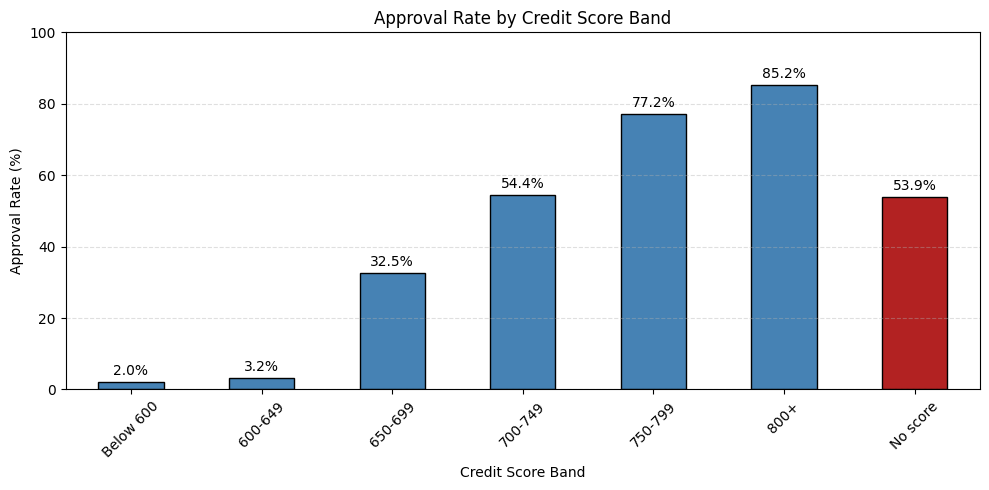

In [11]:
plt.figure(figsize=(10, 5))

colors = ["steelblue"] * 6 + ["firebrick"]
ax = approval_by_score.plot(kind="bar", color=colors, edgecolor="black")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Approval Rate by Credit Score Band")
plt.xlabel("Credit Score Band")
plt.ylabel("Approval Rate (%)")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## Approval Rate by Employment Type

### Findings

| Employment type | Approval rate | Median years in current job |
|---|---:|---:|
| Salaried | 58.37% | 3.3 |
| Business Owner | 51.17% | 3.1 |
| Self-Employed Professional | 50.56% | 3.3 |
| Gig / Contract | 34.94% | 1.6 |

### Business Interpretation

Gig / Contract applicants are approved least (34.9%), against 58.4% for Salaried. They also have about half the job tenure (1.6 vs about 3.3 years), which suggests the credit team is reacting to income stability and not only to the label. These are associations from historical decisions; they do not prove that any group is less creditworthy.

In [12]:
approval_by_employment = (
    df.groupby("employment_type")["decision"]
      .apply(lambda x: (x == "Approved").mean() * 100)
      .sort_values(ascending=False)
)

print(approval_by_employment.round(2))

print("\nMedian years in current job by employment type:")
print(df.groupby("employment_type")["years_in_current_job"].median().round(1))

employment_type
Salaried                      58.37
Business Owner                51.17
Self-Employed Professional    50.56
Gig / Contract                34.94
Name: decision, dtype: float64

Median years in current job by employment type:
employment_type
Business Owner                3.1
Gig / Contract                1.6
Salaried                      3.3
Self-Employed Professional    3.3
Name: years_in_current_job, dtype: float64


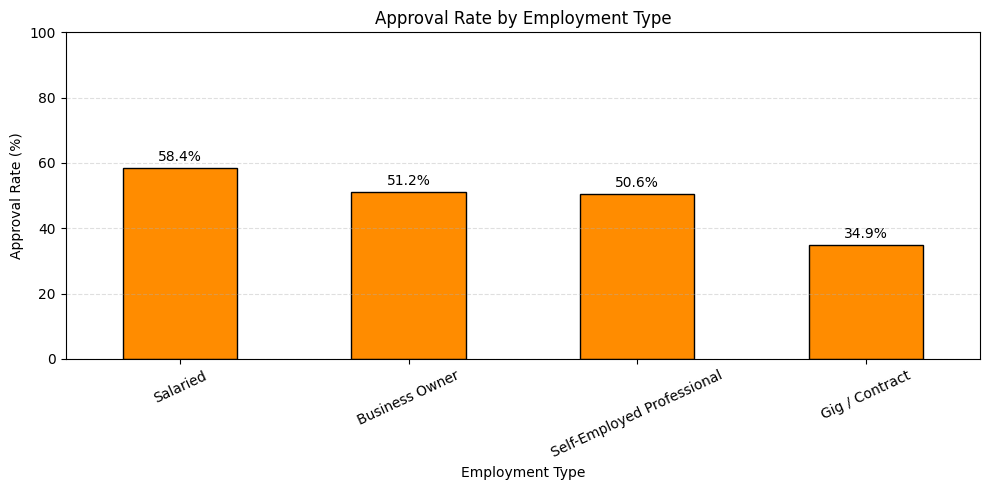

In [13]:
plt.figure(figsize=(10, 5))

ax = approval_by_employment.plot(kind="bar", color="darkorange", edgecolor="black")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Approval Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Approval Rate (%)")
plt.xticks(rotation=25)
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

---
# Step 5.3 — Affordability Feature Engineering
*Built by: **Ashika***

## Features Created

**1. Fixed Obligation to Income Ratio (FOIR)** = (Existing EMI + Proposed EMI) / Monthly Income — the share of income committed to repayments.

**2. Loan-to-Income Ratio** = Loan Amount / (Monthly Income × 12).

**3. New-to-credit flag (`is_ntc`)** = 1 if the applicant has no credit score, otherwise 0 (created in the cleaning step, before the score was filled).

**4. FOIR bands:** Below 30%, 30–40%, 40–50%, 50–55%, Above 55%.

In [14]:
# Calculate FOIR
df["foir"] = (
    (df["existing_emi"] + df["proposed_emi"])
    / df["monthly_income"]
)

# Calculate loan-to-income ratio
df["loan_to_income"] = (
    df["loan_amount"] / (df["monthly_income"] * 12)
)

# (is_ntc was created in the cleaning step: 1 = no credit score, 0 = has a score)

# Create FOIR bands
foir_bins = [0, 0.30, 0.40, 0.50, 0.55, float("inf")]

foir_labels = [
    "Below 30%",
    "30-40%",
    "40-50%",
    "50-55%",
    "Above 55%"
]

df["foir_band"] = pd.cut(
    df["foir"],
    bins=foir_bins,
    labels=foir_labels,
    right=False
)

# Check the calculated features
print(df[["foir", "loan_to_income", "is_ntc"]].describe().round(3))

display(
    df[
        [
            "monthly_income",
            "existing_emi",
            "proposed_emi",
            "foir",
            "loan_to_income",
            "is_ntc",
            "foir_band"
        ]
    ].head(10)
)

            foir  loan_to_income     is_ntc
count  12000.000       12000.000  12000.000
mean       0.358           0.531      0.087
std        0.207           0.225      0.281
min        0.005           0.015      0.000
25%        0.214           0.346      0.000
50%        0.317           0.519      0.000
75%        0.450           0.699      0.000
max        3.393           2.778      1.000


,monthly_income,existing_emi,proposed_emi,foir,loan_to_income,is_ntc,foir_band
0,95000.0,23500.0,6600.0,0.316842,0.210526,0,30-40%
1,43000.0,8500.0,5000.0,0.313953,0.281008,0,30-40%
2,35000.0,3500.0,11800.0,0.437143,0.821429,0,40-50%
3,44500.0,0.0,4600.0,0.103371,0.252809,1,Below 30%
4,83500.0,6000.0,33600.0,0.474251,0.698603,0,40-50%
5,105000.0,6000.0,12100.0,0.172381,0.281746,0,Below 30%
6,30000.0,2000.0,14800.0,0.560000,0.458333,0,Above 55%
7,75000.0,16500.0,37700.0,0.722667,0.872222,0,Above 55%
8,74500.0,19000.0,21800.0,0.547651,0.508949,0,50-55%
9,69500.0,5500.0,26700.0,0.463309,0.935252,0,40-50%


## Approval Rate by FOIR Band

### Findings

| FOIR band | Applicants | Approval rate |
|---|---:|---:|
| Below 30% | 5,491 | 65.47% |
| 30–40% | 2,497 | 58.99% |
| 40–50% | 1,766 | 47.85% |
| 50–55% | 531 | 32.39% |
| Above 55% | 1,715 | 15.63% |

### Business Interpretation

Approval falls steadily as FOIR rises, and the two biggest drops come when EMIs pass **50% of income** (−15 points) and **55%** (−17 points). **Once EMIs take more than half of income, approvals collapse.**

**Proposed policy:** a standard FOIR ceiling of **50%**, with 50–55% allowed only as a manual-review exception with analyst sign-off, and anything above 55% declined unless there are strong offsetting factors. FOIR is a feature the team built, and it turns out to be the strongest driver in the model (Step 5.4).

In [15]:
# Calculate approval rate for each FOIR band
approval_by_foir = (
    df.groupby("foir_band", observed=False)["decision"]
      .apply(lambda x: (x == "Approved").mean() * 100)
)

print("Approval Rate by FOIR Band:")
print(approval_by_foir.round(2))

print("\nApplicants per band:")
print(df["foir_band"].value_counts().reindex(foir_labels))

Approval Rate by FOIR Band:
foir_band
Below 30%    65.47
30-40%       58.99
40-50%       47.85
50-55%       32.39
Above 55%    15.63
Name: decision, dtype: float64

Applicants per band:
foir_band
Below 30%    5491
30-40%       2497
40-50%       1766
50-55%        531
Above 55%    1715
Name: count, dtype: int64


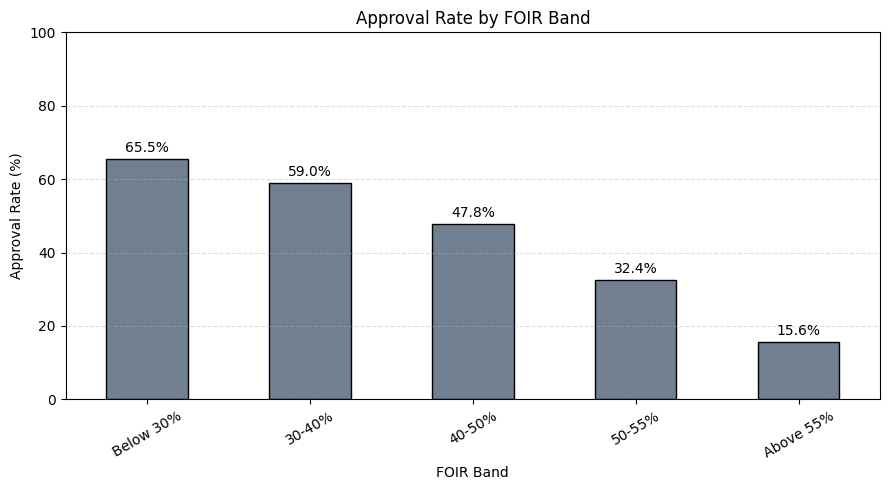

In [16]:
plt.figure(figsize=(9, 5))

ax = approval_by_foir.plot(kind="bar", color="slategray", edgecolor="black")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Approval Rate by FOIR Band")
plt.xlabel("FOIR Band")
plt.ylabel("Approval Rate (%)")
plt.xticks(rotation=30)
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

---
# Step 5.4 — Logistic Regression Pre-Screener
*Built by: **Suresh***

## Model Setup

### Objective

Predict **Declined (target = 1)**; Approved = 0. Positive coefficients therefore push an application **towards decline**.

### Features Used (as specified)

`credit_score, is_ntc, foir, loan_to_income, delinquencies_24m, num_active_loans, years_in_current_job, age, tenure_months, city_tier, employment_type, loan_purpose`

**Not used:** `application_id`, `application_date`, `city`, `gender`, `decision`. An assertion in the code checks that none of them is in the feature matrix. The split is 80/20 with `stratify=y` and `random_state=42`, and it is done **first**. A scikit-learn `Pipeline` then (1) fills missing income (median by employment type) and missing credit score (overall median) using **training rows only**, (2) builds FOIR and loan-to-income from the filled values, (3) standardises the numeric features and one-hot encodes `employment_type` and `loan_purpose`, and (4) fits the logistic regression. The same training-set medians and scaling are applied to the test set, so no test-set information influences preprocessing.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    roc_auc_score
)

In [ ]:
# Target: 1 = Declined, 0 = Approved
y = (df_model_base["decision"] == "Declined").astype(int)

# Features used by the model (exactly the list required by the assignment)
numeric_features = [
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier"
]
categorical_features = [
    "employment_type",
    "loan_purpose"
]

# Raw inputs. Missing monthly_income / credit_score are still missing here, and FOIR and
# loan_to_income are NOT built yet: that happens inside the pipeline, after the split.
raw_inputs = [
    "credit_score", "is_ntc", "delinquencies_24m", "num_active_loans",
    "years_in_current_job", "age", "tenure_months", "city_tier",
    "employment_type", "loan_purpose",
    "monthly_income", "existing_emi", "proposed_emi", "loan_amount"   # only used to build FOIR / loan_to_income
]
X = df_model_base[raw_inputs]

# Leakage check: none of these may be an input
forbidden = {"decision", "gender", "city", "application_id", "application_date"}
assert forbidden.isdisjoint(X.columns), "A forbidden column is in the feature matrix"

print("Raw input matrix:", X.shape)
print("Missing values still present (to be filled from training data only):")
print(X[["monthly_income", "credit_score"]].isnull().sum())
print("\nTarget distribution (1 = Declined, 0 = Approved):")
print(y.value_counts())

In [ ]:
# Split FIRST, before any median or scaling is calculated
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Decline rate - train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))
print("Missing in train:", X_train[["monthly_income", "credit_score"]].isnull().sum().to_dict(),
      "| missing in test:", X_test[["monthly_income", "credit_score"]].isnull().sum().to_dict())

In [ ]:
class CreditPreparer(BaseEstimator, TransformerMixin):
    """Learns medians from the data passed to fit() (training rows only), fills missing
    monthly_income / credit_score, and builds FOIR and loan_to_income from the filled values."""

    def fit(self, X, y=None):
        self.income_median_by_type_ = X.groupby("employment_type")["monthly_income"].median()
        self.income_median_all_ = X["monthly_income"].median()
        self.score_median_ = X["credit_score"].median()
        return self

    def transform(self, X):
        X = X.copy()
        income_fill = X["employment_type"].map(self.income_median_by_type_).fillna(self.income_median_all_)
        X["monthly_income"] = X["monthly_income"].fillna(income_fill)
        X["credit_score"] = X["credit_score"].fillna(self.score_median_)
        X["foir"] = (X["existing_emi"] + X["proposed_emi"]) / X["monthly_income"]
        X["loan_to_income"] = X["loan_amount"] / (X["monthly_income"] * 12)
        return X[numeric_features + categorical_features]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),                          # fitted on training data only
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

pipeline = Pipeline([
    ("prepare", CreditPreparer()),
    ("encode_scale", preprocess),
    ("logreg", LogisticRegression(max_iter=1000))
])

pipeline.fit(X_train, y_train)

# Predict decisions (default 0.5 cut-off) - the test set is transformed with TRAINING medians/scaling
y_pred = pipeline.predict(X_test)

# Probability that an application will be declined
y_prob = pipeline.predict_proba(X_test)[:, 1]

# Keep the fitted logistic regression and feature names for the coefficient step
model = pipeline.named_steps["logreg"]
feature_names = [n.split("__", 1)[1] for n in pipeline.named_steps["encode_scale"].get_feature_names_out()]

prep = pipeline.named_steps["prepare"]
print("Medians learned from TRAINING rows only:")
print(f"  credit score median          : {prep.score_median_:.0f}")
print("  income median by employment type:")
print(prep.income_median_by_type_.round(0).to_string())
print("\nModel training completed successfully!")

## Model Evaluation

### Findings (threshold 0.5, 2,400 test applications)

| Metric | Value |
|---|---:|
| Accuracy | 79.08% |
| ROC-AUC | 0.867 |
| Precision (Declined) | 79.16% |
| Recall (Declined) | 75.38% |
| Accuracy — scored applicants | 81.2% |
| Accuracy — new-to-credit applicants | 56.7% |

### Confusion Matrix in Business Language

- **1,047** approved applications were correctly kept as approvals.
- **851** declines were correctly identified.
- **224 creditworthy applicants — whom the credit team approved — would have been wrongly declined.** That is 17.6% of the 1,271 applications the bank actually approved. This is the number the bank cares about, not the 79% accuracy.
- **278** actual declines were missed; they would still go to an analyst, which is safe but costs analyst time.

The model is also **much weaker on new-to-credit applicants (56.7% vs 81.2%)** — barely better than a coin toss.

In [21]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("\nConfusion Matrix:")
print(pd.DataFrame(
    cm,
    index=["Actually Approved", "Actually Declined"],
    columns=["Predicted Approved", "Predicted Declined"]
))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Approved", "Declined"]
    )
)

print(f"Precision (Declined): {precision_score(y_test, y_pred):.2%}")
print(f"Recall (Declined)   : {recall_score(y_test, y_pred):.2%}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")

print(f"\nGood customers wrongly declined at 0.5 (false positives): {fp}"
      f"  ({fp / (tn + fp):.1%} of the {tn + fp} applications the bank approved)")
print(f"Declines the model missed (false negatives): {fn}")

# Scored vs new-to-credit accuracy
ntc_test = df.loc[X_test.index, "is_ntc"] == 1
print(f"\nAccuracy - scored applicants : {accuracy_score(y_test[~ntc_test], y_pred[~ntc_test.values]):.1%}")
print(f"Accuracy - new-to-credit     : {accuracy_score(y_test[ntc_test], y_pred[ntc_test.values]):.1%}")

Accuracy: 79.08%

Confusion Matrix:
                   Predicted Approved  Predicted Declined
Actually Approved                1046                 225
Actually Declined                 277                 852

Classification Report:
              precision    recall  f1-score   support

    Approved       0.79      0.82      0.81      1271
    Declined       0.79      0.75      0.77      1129

    accuracy                           0.79      2400
   macro avg       0.79      0.79      0.79      2400
weighted avg       0.79      0.79      0.79      2400

Precision (Declined): 79.11%
Recall (Declined)   : 75.47%
ROC-AUC: 0.867

Good customers wrongly declined at 0.5 (false positives): 225  (17.7% of the 1271 applications the bank approved)
Declines the model missed (false negatives): 277

Accuracy - scored applicants : 81.2%
Accuracy - new-to-credit     : 56.7%


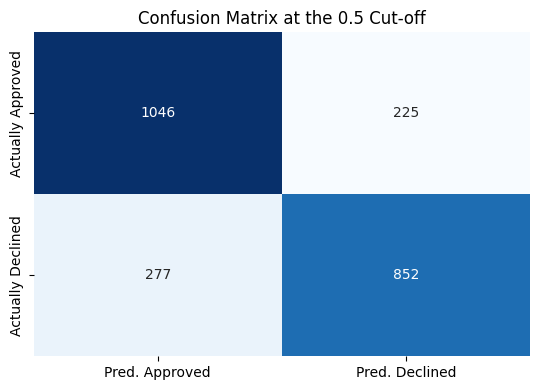

In [22]:
fig, ax = plt.subplots(figsize=(5.5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Pred. Approved", "Pred. Declined"],
    yticklabels=["Actually Approved", "Actually Declined"],
    ax=ax
)
ax.set_title("Confusion Matrix at the 0.5 Cut-off")
plt.tight_layout()
plt.show()

## Model Coefficients

### Top 5 Features, Explained for a Credit Analyst

Numeric features are standardized, while one-hot encoded categorical features remain binary. Coefficient magnitudes therefore require caution when comparing numerical and categorical features. Positive = pushes towards decline; negative = pulls towards approval.

1. **FOIR (+1.22)** — the strongest driver. The more of an applicant's income is already committed to EMIs, the more the application is pushed towards decline.
2. **Credit score (−1.01)** — a higher score pulls strongly towards approval; low scores push towards decline.
3. **Delinquencies in the last 24 months (+0.98)** — every additional late or missed repayment pushes the application towards decline.
4. **Gig / Contract employment (+0.62)** — gig workers are pushed towards decline even at the same FOIR and score, reflecting income instability.
5. **Salaried employment (−0.45)** — a salaried job pulls towards approval.

The model has therefore **learned the same policy we found by hand in Steps 5.2 and 5.3** — affordability, credit score and repayment behaviour. The model identifies patterns in historical decisions, but these patterns require validation against actual repayment outcomes.

In [ ]:
# Extract Logistic Regression coefficients
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": model.coef_[0]
})

# Sort by absolute size
feature_importance["absolute_coefficient"] = (
    feature_importance["coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "absolute_coefficient",
    ascending=False
)

feature_importance["pushes_towards"] = np.where(
    feature_importance["coefficient"] > 0, "DECLINE", "APPROVAL"
)

print("Top 5 features by absolute coefficient:")
display(feature_importance.head(5).round(3))

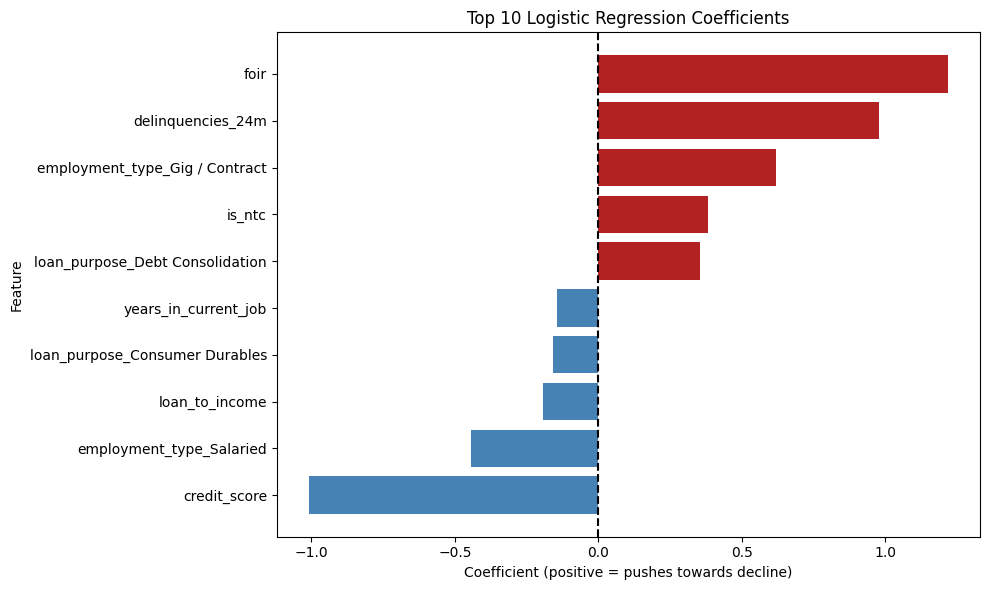

In [24]:
top_features = feature_importance.head(10).sort_values(
    "coefficient"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"],
    top_features["coefficient"],
    color=["firebrick" if c > 0 else "steelblue" for c in top_features["coefficient"]]
)

plt.axvline(0, linestyle="--", color="black")
plt.title("Top 10 Logistic Regression Coefficients")
plt.xlabel("Coefficient (positive = pushes towards decline)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

---
# Step 5.5 — Auto-Decline Threshold
*Built by: **Suresh***

## Objective

At the default 0.5 cut-off the model would turn away many good customers. Instead the bank will auto-decline **only when the model is very confident**. Using `predict_proba` on the test set we test thresholds 0.50, 0.60, 0.70, 0.80, 0.85, 0.90 and 0.95 and record:

- the **% of applications auto-declined**, and
- of those, the **% the credit team actually approved** (wrongly declined).

**Bank's risk appetite:** no more than **5%** of auto-declined applications may be ones the credit team would have approved. The code applies this rule to the **unrounded** values and picks the threshold that auto-declines the **most** applications while meeting it.

> Note: "wrongly declined" here is measured **as a share of the auto-declined applications**, as the assignment defines it — not as a share of all approved applications.

In [25]:
# Threshold analysis table required by the assignment
thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]

actual_declined = (y_test == 1).values
rows = []

for threshold in thresholds:
    # Auto-decline only when the model is at least this confident
    auto_decline = y_prob >= threshold
    n_auto = int(auto_decline.sum())

    # Of the auto-declined, how many did the credit team actually APPROVE?
    wrong = int((auto_decline & ~actual_declined).sum())

    rows.append({
        "threshold": threshold,
        "auto_declined_n": n_auto,
        "auto_declined_pct": n_auto / len(y_prob) * 100,
        "wrongly_declined_n": wrong,
        "wrongly_declined_pct": wrong / n_auto * 100 if n_auto else 0.0,
        "declines_caught_pct": (auto_decline & actual_declined).sum() / actual_declined.sum() * 100
    })

# Unrounded table is used for the decision; the rounded copy is only for display
threshold_results = pd.DataFrame(rows).set_index("threshold")
display(threshold_results.round(2))

# 5% rule on UNROUNDED values: choose the threshold that auto-declines the most applications
RISK_LIMIT = 5.0
safe = threshold_results[threshold_results["wrongly_declined_pct"] <= RISK_LIMIT]

if safe.empty:
    raise ValueError("No tested threshold meets the 5% limit")

chosen_threshold = safe["auto_declined_n"].idxmax()
print(f"Thresholds meeting the {RISK_LIMIT}% limit: {list(safe.index)}")
print(f"\nChosen threshold: {chosen_threshold}")
print(threshold_results.loc[chosen_threshold].round(3))

Thresholds meeting the 5.0% limit: [0.9, 0.95]

Chosen threshold: 0.9
auto_declined_n         365.000
auto_declined_pct        15.208
wrongly_declined_n       17.000
wrongly_declined_pct      4.658
declines_caught_pct      30.824
Name: 0.9, dtype: float64


,auto_declined_n,auto_declined_pct,wrongly_declined_n,wrongly_declined_pct,declines_caught_pct
threshold,,,,,
0.50,1077,44.88,225,20.89,75.47
0.60,903,37.62,152,16.83,66.52
0.70,738,30.75,89,12.06,57.48
0.80,563,23.46,40,7.10,46.32
0.85,472,19.67,28,5.93,39.33
0.90,365,15.21,17,4.66,30.82
0.95,240,10.00,5,2.08,20.81


### Findings

| Threshold | Auto-declined | Wrongly declined |
|---|---:|---:|
| 0.50 | 44.8% | 20.8% |
| 0.60 | 37.6% | 16.9% |
| 0.70 | 30.8% | 12.1% |
| 0.80 | 23.5% | 6.9% |
| 0.85 | 19.7% | 5.9% |
| **0.90** | **15.2%** | **4.7%** |
| 0.95 | 10.0% | 2.1% |

### Business Interpretation

At the default **0.50**, 44.8% of applications would be auto-declined but **20.8% of them (one in five) were approved by the credit team**. At 0.85 the wrong-decline rate is 5.9% — still above the limit. **0.90 is the threshold that meets the 5% rule while auto-declining the most applications** (15.2% auto-declined, 4.66% wrong). 0.95 is safer (2.1%) but auto-declines only 10%. The bank sets the risk limit; the model only shows where that limit falls.

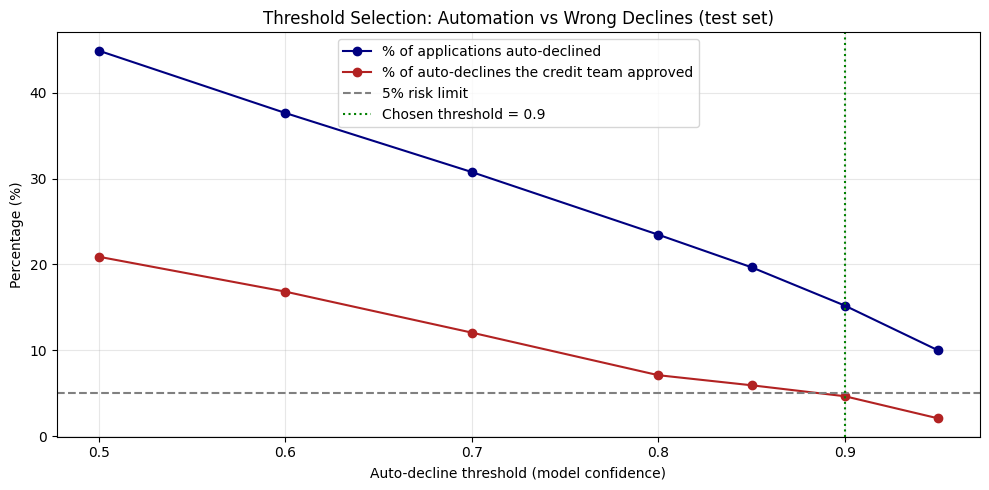

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(threshold_results.index, threshold_results["auto_declined_pct"],
        marker="o", color="navy", label="% of applications auto-declined")
ax.plot(threshold_results.index, threshold_results["wrongly_declined_pct"],
        marker="o", color="firebrick", label="% of auto-declines the credit team approved")
ax.axhline(RISK_LIMIT, linestyle="--", color="gray", label="5% risk limit")
ax.axvline(chosen_threshold, linestyle=":", color="green", label=f"Chosen threshold = {chosen_threshold}")

ax.set_xlabel("Auto-decline threshold (model confidence)")
ax.set_ylabel("Percentage (%)")
ax.set_title("Threshold Selection: Automation vs Wrong Declines (test set)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [27]:
# Cross-check on a finer grid (0.50 to 0.99): is 0.90 really the lowest threshold within the limit?
fine = []
for t in np.arange(0.50, 1.00, 0.01):
    a = y_prob >= t
    if a.sum() == 0:
        continue
    fine.append({"threshold": round(t, 2),
                 "auto_declined_n": int(a.sum()),
                 "wrongly_declined_pct": (a & ~actual_declined).sum() / a.sum() * 100})
fine = pd.DataFrame(fine)
print(fine[(fine["threshold"] >= 0.84) & (fine["threshold"] <= 0.95)].round(2).to_string(index=False))
first_ok = fine[fine["wrongly_declined_pct"] <= RISK_LIMIT]["threshold"].min()
print(f"\nLowest threshold within the 5% limit on the fine grid: {first_ok}")

 threshold  auto_declined_n  wrongly_declined_pct
      0.84              495                  6.26
      0.85              472                  5.93
      0.86              448                  5.36
      0.87              426                  5.40
      0.88              407                  5.41
      0.89              390                  5.64
      0.90              365                  4.66
      0.91              338                  4.44
      0.92              318                  4.09
      0.93              292                  3.77
      0.94              262                  2.67
      0.95              240                  2.08

Lowest threshold within the 5% limit on the fine grid: 0.9


The finer grid confirms the choice: thresholds 0.86–0.89 all give 5.3–5.6% wrong declines, so **0.90 is the lowest threshold within the limit**.

## Monthly Business Case

In [28]:
APPS_PER_MONTH = 3000
MIN_PER_REVIEW = 25

res = threshold_results.loc[chosen_threshold]

apps_freed = APPS_PER_MONTH * res["auto_declined_pct"] / 100
hours_freed = apps_freed * MIN_PER_REVIEW / 60
good_lost = apps_freed * res["wrongly_declined_pct"] / 100

print(f"Chosen threshold                          : {chosen_threshold}")
print(f"Share of applications auto-declined       : {res['auto_declined_pct']:.1f}%")
print(f"Applications removed from review / month  : ~{apps_freed:,.0f} of {APPS_PER_MONTH:,}")
print(f"Analyst hours freed per month             : ~{hours_freed:,.0f} hours")
print(f"Auto-declines the credit team would approve: {res['wrongly_declined_pct']:.1f}% (~{good_lost:,.0f} applications a month)")
print(f"Share of ALL actual declines caught       : {res['declines_caught_pct']:.1f}%")
print(f"Test-set size behind these estimates      : {int(res['auto_declined_n'])} auto-declines, {int(res['wrongly_declined_n'])} of them approved by the credit team")

Chosen threshold                          : 0.9
Share of applications auto-declined       : 15.2%
Applications removed from review / month  : ~456 of 3,000
Analyst hours freed per month             : ~190 hours
Auto-declines the credit team would approve: 4.7% (~21 applications a month)
Share of ALL actual declines caught       : 30.8%
Test-set size behind these estimates      : 365 auto-declines, 17 of them approved by the credit team


In [29]:
# Who is in the auto-decline lane?
auto_lane = y_prob >= chosen_threshold
ntc_mask = (df.loc[X_test.index, "is_ntc"] == 1).values
low_score = (df.loc[X_test.index, "credit_score"] < 650).values & ~ntc_mask

print(f"Auto-declined test applications: {auto_lane.sum()}")
print(f"  new-to-credit applicants     : {(auto_lane & ntc_mask).sum()} "
      f"({(auto_lane & ntc_mask).sum() / ntc_mask.sum():.1%} of all NTC applicants in the test set)")
print(f"  with a credit score below 650: {(auto_lane & low_score).sum()} "
      f"({(auto_lane & low_score).sum() / auto_lane.sum():.1%} of the auto-declines)")

Auto-declined test applications: 365
  new-to-credit applicants     : 12 (5.9% of all NTC applicants in the test set)
  with a credit score below 650: 159 (43.6% of the auto-declines)


### Findings at Threshold 0.90

- **15.2%** of applications auto-declined → about **456 of 3,000 applications a month** leave the manual queue.
- At 25 minutes each, that frees roughly **190 analyst hours a month**.
- About **4.7%** of those auto-declines (roughly **21 applications a month**) would have been approved by the credit team — inside the 5% limit.
- The model catches only about **30.8% of all actual declines** at this strictness. The number is modest, but it is a **safe first step**: the remaining ~70% of declines still go to analysts.
- Only **12 of the 365** auto-declines are new-to-credit applicants; 43.6% of all auto-declines (159 of 365) have a score below 650.

### Caution

The 4.7% is estimated from only 365 auto-declines (17 of them approved by the credit team), so it carries sampling uncertainty and sits close to the limit. It should be re-checked on a fresh month of data before go-live.

---
# Step 5.6 — Fairness Check
*Built by: **Akhilandra***

## Objective

Gender was **not** used as a feature, but that does not automatically make the model fair. We check (1) historical approval by gender, overall and within employment type, (2) income and job mix by gender, and (3) the model's auto-decline rate by gender.

Approval rate by gender (overall, %):
gender
Female    50.4
Male      54.1
Name: decision, dtype: float64

Approval rate (%) by gender within employment type:
gender                      Female  Male  gap (Male - Female)
employment_type                                              
Business Owner                51.6  51.1                 -0.5
Gig / Contract                34.6  35.2                  0.6
Salaried                      56.8  59.1                  2.3
Self-Employed Professional    47.6  52.0                  4.4


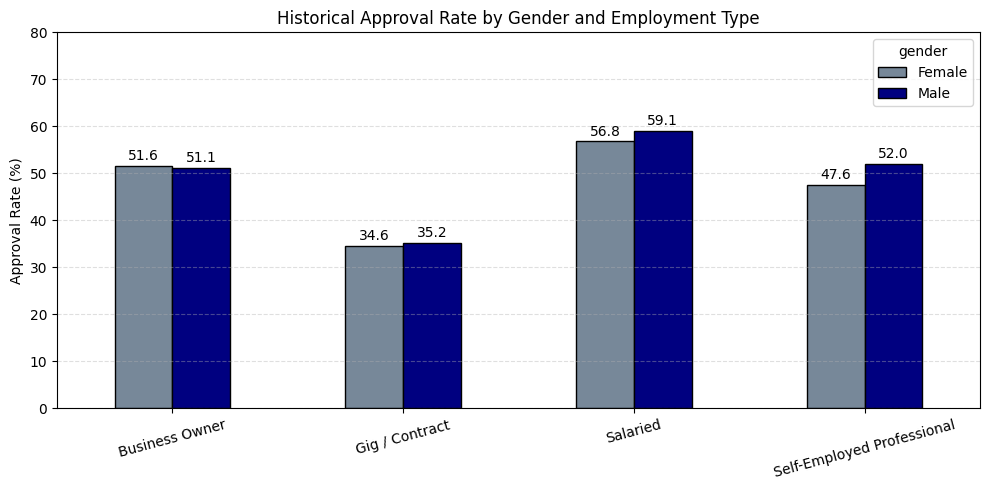

In [30]:
# Historical approval rate by gender - overall
gender_overall = (
    df.groupby("gender")["decision"]
      .apply(lambda x: (x == "Approved").mean() * 100)
      .round(1)
)
print("Approval rate by gender (overall, %):")
print(gender_overall)

# ...and within each employment type
gender_emp = (
    df.pivot_table(
        index="employment_type",
        columns="gender",
        values="decision",
        aggfunc=lambda x: (x == "Approved").mean() * 100
    ).round(1)
)
gender_emp["gap (Male - Female)"] = (gender_emp["Male"] - gender_emp["Female"]).round(1)
print("\nApproval rate (%) by gender within employment type:")
print(gender_emp)

ax = gender_emp[["Female", "Male"]].plot(
    kind="bar", figsize=(10, 5), color=["lightslategray", "navy"], edgecolor="black", rot=15
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=2)
plt.title("Historical Approval Rate by Gender and Employment Type")
plt.ylabel("Approval Rate (%)")
plt.xlabel("")
plt.ylim(0, 80)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [31]:
# Income and job mix by gender
gender_profile = df.groupby("gender").agg(
    median_monthly_income=("monthly_income", "median"),
    gig_worker_share_pct=("employment_type", lambda x: (x == "Gig / Contract").mean() * 100),
    median_credit_score=("credit_score", "median"),
    average_foir=("foir", "mean")
).round(2)

display(gender_profile)

,median_monthly_income,gig_worker_share_pct,median_credit_score,average_foir
gender,,,,
Female,45000.0,21.37,726.0,0.36
Male,55000.0,11.64,726.0,0.36


In [32]:
# Model auto-decline rate by gender (test set)
test_gender = df.loc[X_test.index, "gender"].values
fair_rows = []

for t in [0.50, 0.80, chosen_threshold]:
    auto = y_prob >= t
    for g in ["Female", "Male"]:
        m = test_gender == g
        n_auto = int((auto & m).sum())
        n_wrong = int((auto & m & ~actual_declined).sum())
        fair_rows.append({
            "threshold": t,
            "gender": g,
            "applicants": int(m.sum()),
            "auto_declined_n": n_auto,
            "auto_decline_rate_pct": n_auto / m.sum() * 100,
            "wrongly_declined_n": n_wrong,
            "wrongly_declined_pct": n_wrong / n_auto * 100 if n_auto else np.nan
        })

fair_table = pd.DataFrame(fair_rows)
display(fair_table.round(1))

print("Historical DECLINE rate in the test set (%):")
print(pd.Series(actual_declined, index=test_gender).groupby(level=0).mean().mul(100).round(1))

Historical DECLINE rate in the test set (%):
Female    49.7
Male      45.8
dtype: float64


,threshold,gender,applicants,auto_declined_n,auto_decline_rate_pct,wrongly_declined_n,wrongly_declined_pct
0,0.5,Female,750,359,47.9,74,20.6
1,0.5,Male,1650,718,43.5,151,21.0
2,0.8,Female,750,182,24.3,11,6.0
3,0.8,Male,1650,381,23.1,29,7.6
4,0.9,Female,750,117,15.6,4,3.4
5,0.9,Male,1650,248,15.0,13,5.2


## Fairness Answer

Yes, there is a gap in the historical data: **54.1% of male vs 50.4% of female applicants were approved** (3.7 points). The gender approval gap is associated with differences in income and employment mix, although these descriptive comparisons do not establish causation or fully explain the gap. Female applicants have a lower median income (**₹45,000 vs ₹55,000**) and are almost **twice as likely to be Gig / Contract workers (21.4% vs 11.6%)**, the group with the lowest approval. Within Gig and Business Owner applicants the gap is under 1 point, though a gap remains for Salaried (2.3 points) and especially **Self-Employed Professionals (4.4 points)**, which income and job mix alone do not explain and which needs monitoring.

At our threshold the model's auto-decline rate is very close by gender (**15.6% female vs 15.0% male at 0.90**; 24.4% vs 23.1% at 0.80). At the default 0.5 the predicted-decline rate is 47.9% vs 43.4% (a 4.5-point gap, against a 3.9-point historical decline gap in the same test set), so the model **roughly reproduces the historical gap rather than closing it**; in the 0.90 auto-decline lane the gap is small (0.6 points). At 0.90 the wrongly-declined share is 3.4% for women (4 of 117) and 5.2% for men (13 of 248) — very small counts that should be tracked.

Gender should **never be used as a feature** in a credit model, because a bank cannot defend it. But **leaving it out is necessary, not sufficient**: income and employment type can act as proxies, so outcomes by gender must be monitored every month after launch.

---
# Credit Policy Briefing
*Written by: **Akhilandra**, using findings from all sections.*

"I recommend piloting auto-declines, only when the model is at least **90% confident** it will be declined. On our test data that removes about **15.2% of applications — roughly 456 a month, or about 190 analyst hours** — and **4.7%** of those would have been approved by the credit team, inside the bank's 5% limit but close to it (4.66%) (at the default 0.5 it would be 20.8%, so the threshold matters). Two factors drive decisions most strongly: **FOIR**, where approvals fall from **65.5% below 30% to 15.6% above 55%**, and **credit score**, where approvals are only **3.0% below 650** against 58.9% above it. The model should **not decide on new-to-credit applicants** — it is right only **56.7%** of the time for them, and the credit team approves them 53.9% of the time through judgement — so they should always go to an analyst. Gender is not used and auto-decline rates are almost identical by gender (15.6% vs 15.0%), but income and job type can act as proxies, so I would report outcomes by gender every month. Before going live I would want **actual repayment data (defaults)**, because today the model copies past analyst decisions, not whether customers repaid. The 90% threshold should be validated on a fresh, out-of-time dataset and reviewed for fairness before any production deployment."

---
### Notes for Reviewers

- All results come from a single 80/20 split with `random_state=42`.
- The model's imputation medians and scaling are learned from the training rows only (Step 5.4 pipeline); Steps 5.2, 5.3 and 5.6 are descriptive and use a separately filled copy of the data.
- The 90% threshold is a candidate for a controlled pilot, not an approved production policy.
- The dataset CSV must be in the same folder as the notebook.
- Verify with **Kernel → Restart & Run All**.